In [ ]:
!pip install mujoco mediapy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.6/30.6 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 66.5 MB/s eta 0:00:00


In [ ]:

import os

# MUST be set before importing mujoco
os.environ["MUJOCO_GL"] = "egl"

# Colab has no X11 display
os.environ.pop("DISPLAY", None)

print("MUJOCO_GL =", os.environ["MUJOCO_GL"])
print("DISPLAY    =", os.environ.get("DISPLAY"))

MUJOCO_GL = egl
DISPLAY    = None


In [ ]:
# ============================================================
# CELL 1 — Parameters and genome layout
# ============================================================

import numpy as np
from dataclasses import dataclass

# ---- Sheet (S x S) ----
S          = 1.0
THICK      = 0.0001          # half thickness (m)
PAPER_MASS = 0.2            # kg, spread over all faces by area
Z0         = THICK + 0.001  # start just above the table

# ---- Genome: N_MAX creases x 6 genes ----
N_MAX      = 8
GENES      = 6              # x1, y1, x2, y2, angle, active
GENOME_LEN = N_MAX * GENES
GENE_LOW   = np.tile([0, 0, 0, 0, -np.pi, 0], N_MAX)
GENE_HIGH  = np.tile([S, S, S, S,  np.pi, 1], N_MAX)
# angle > 0 = valley, angle < 0 = mountain, active > 0.5 = crease used

# ---- Pattern options ----
EXTEND_MODE   = "chord"     # "chord" or "segment"
SNAP_TOL      = 0.02        # segment mode: snap endpoints to nearby crease/boundary
GRID          = 1e-4        # coordinate rounding (avoids numerical slivers)
MIN_FACE_AREA = 1e-4 * S * S
MAX_FOLD      = np.pi * 0.98

# ---- Physics ----
KP, KV, DAMPING, FORCE_MAX = 20.0, 1.0, 0.05, 10.0
MU_PAPER = 0.4
MU_TABLE = 0.4
EQ_SOLREF = "0.005 1"       # stiffness of the closed-loop hinges

# ---- Table vibration ----
VIB_FREQ  = 0.0
VIB_AMP_X = 0.0
VIB_AMP_Z = 0.0

In [ ]:
# ============================================================
# CELL 2 — Genome -> crease segments
# ============================================================

from shapely.geometry import LineString, Point, box
from shapely.ops import unary_union, polygonize, linemerge, nearest_points

@dataclass
class Crease:
    p1: tuple
    p2: tuple
    angle: float    # rad, + valley / - mountain
    gene: int       # which gene slot it came from


def clip_to_square(p, d, t0, t1):
    """Clip p + t*d (t in [t0, t1]) to the square [0, S]^2 (Liang-Barsky)."""
    for k in range(2):
        if abs(d[k]) < 1e-12:
            if p[k] < 0 or p[k] > S:
                return None
        else:
            ta, tb = (0 - p[k]) / d[k], (S - p[k]) / d[k]
            if ta > tb:
                ta, tb = tb, ta
            t0, t1 = max(t0, ta), min(t1, tb)
            if t0 > t1:
                return None
    return p + t0 * d, p + t1 * d


def snap_endpoints(segs, tol):
    boundary = box(0, 0, S, S).exterior
    out = []
    for i, (a, b, ang, k) in enumerate(segs):
        others = [LineString([s[0], s[1]]) for j, s in enumerate(segs) if j != i]
        targets = unary_union([boundary] + others)
        new = []
        for p in (a, b):
            pt = Point(p)
            if targets.distance(pt) < tol:
                q = nearest_points(targets, pt)[0]
                new.append((q.x, q.y))
            else:
                new.append(tuple(p))
        out.append((new[0], new[1], ang, k))
    return out


def decode_genome(genome, mode=None):
    mode = mode or EXTEND_MODE
    g = np.asarray(genome, float).reshape(N_MAX, GENES)
    segs = []
    for k, (x1, y1, x2, y2, ang, act) in enumerate(g):
        if act <= 0.5:
            continue
        p = np.array([x1, y1]); d = np.array([x2 - x1, y2 - y1])
        if np.linalg.norm(d) < 1e-3:
            continue
        res = clip_to_square(p, d, -1e3, 1e3) if mode == "chord" \
              else clip_to_square(p, d, 0.0, 1.0)
        if res is None:
            continue
        a, b = (np.round(r / GRID) * GRID for r in res)
        if np.linalg.norm(b - a) < 1e-3:
            continue
        segs.append((tuple(a), tuple(b), float(ang), k))

    if mode == "segment" and SNAP_TOL > 0:
        segs = snap_endpoints(segs, SNAP_TOL)

    return [Crease(a, b, ang, k) for a, b, ang, k in segs
            if np.hypot(b[0] - a[0], b[1] - a[1]) > 1e-3]

In [ ]:
# ============================================================
# CELL 3 — Crease segments -> faces, hinge graph, spanning tree
# ============================================================

@dataclass
class Pattern:
    valid: bool
    reason: str = ""
    faces: list = None
    edges: list = None        # dicts: i, j, p, q, crease
    root: int = 0
    parent: dict = None
    depth: dict = None
    tree_edge: dict = None    # child face -> edge index
    loop_edges: list = None   # edges NOT in the tree (closed-loop constraints)


def _parts(g):
    return list(g.geoms) if hasattr(g, "geoms") else [g]


def _straight_pieces(g):
    lines = [x for x in _parts(g) if x.geom_type == "LineString"]
    if not lines:
        return []
    out = []
    for part in _parts(linemerge(lines)):
        c = list(part.simplify(1e-9).coords)
        out += [(c[i], c[i + 1]) for i in range(len(c) - 1)
                if np.hypot(c[i + 1][0] - c[i][0], c[i + 1][1] - c[i][1]) > 1e-6]
    return out


def build_pattern(creases):
    lines = [LineString([c.p1, c.p2]) for c in creases]
    noded = unary_union([box(0, 0, S, S).exterior] + lines)
    faces = list(polygonize(_parts(noded)))
    if not faces:
        return Pattern(False, "no faces")

    areas = np.array([f.area for f in faces])
    if areas.min() < MIN_FACE_AREA:
        return Pattern(False, f"sliver face (area {areas.min():.2e})")
    if abs(areas.sum() - S * S) > 1e-6:
        return Pattern(False, "faces do not tile the sheet")

    # ---- shared edges between faces ----
    bnd = [f.boundary for f in faces]
    edges = []
    for i in range(len(faces)):
        for j in range(i + 1, len(faces)):
            if not faces[i].intersects(faces[j]):
                continue
            for p, q in _straight_pieces(bnd[i].intersection(bnd[j])):
                mid = Point((p[0] + q[0]) / 2, (p[1] + q[1]) / 2)
                dist = [ln.distance(mid) for ln in lines]
                k = int(np.argmin(dist)) if dist else -1
                if k >= 0 and dist[k] > 1e-6:
                    k = -1
                edges.append(dict(i=i, j=j, p=p, q=q, crease=k))

    # ---- spanning tree (BFS from the biggest face) ----
    adj = {i: [] for i in range(len(faces))}
    for k, e in enumerate(edges):
        adj[e["i"]].append((e["j"], k))
        adj[e["j"]].append((e["i"], k))

    root = int(np.argmax(areas))
    parent, depth, tree_edge = {root: None}, {root: 0}, {}
    queue = [root]
    while queue:
        u = queue.pop(0)
        for v, k in adj[u]:
            if v not in parent:
                parent[v], depth[v], tree_edge[v] = u, depth[u] + 1, k
                queue.append(v)

    if len(parent) < len(faces):
        return Pattern(False, "disconnected faces")

    used = set(tree_edge.values())
    loop_edges = [k for k in range(len(edges)) if k not in used]
    return Pattern(True, "", faces, edges, root, parent, depth, tree_edge, loop_edges)

In [ ]:
# ============================================================
# CELL 4 — Pattern -> MuJoCo XML
# ============================================================

def _tri_area(t):
    return 0.5 * abs((t[1][0]-t[0][0])*(t[2][1]-t[0][1]) - (t[2][0]-t[0][0])*(t[1][1]-t[0][1]))


def _triangles(poly):
    if poly.convex_hull.area - poly.area < 1e-12 and not list(poly.interiors):
        c = np.array(poly.exterior.coords)[:-1]
        tris = [(c[0], c[k], c[k + 1]) for k in range(1, len(c) - 1)]
    else:
        try:
            import shapely
            tris = [np.array(t.exterior.coords)[:3]
                    for t in shapely.constrained_delaunay_triangles(poly).geoms]
        except Exception:
            from shapely.ops import triangulate
            tris = [np.array(t.exterior.coords)[:3] for t in triangulate(poly)
                    if poly.contains(t.representative_point())]
    return [np.asarray(t) for t in tris if _tri_area(t) > 1e-7]


def _prism(tri, O):
    v = []
    for x, y in np.asarray(tri)[:, :2]:
        v += [x - O[0], y - O[1], -THICK, x - O[0], y - O[1], THICK]
    return " ".join(f"{a:.6f}" for a in v)


def generate_xml(pat, creases, name="origami_free"):
    faces, edges = pat.faces, pat.edges
    n = len(faces)
    density = PAPER_MASS / (S * S * 2 * THICK)
    mats = ["paper_A", "paper_B"]

    children = {i: [] for i in range(n)}
    for v, u in pat.parent.items():
        if u is not None:
            children[u].append(v)

    # body origin: root = centroid, others = start point of their hinge edge
    origin = {}
    for v in range(n):
        if v == pat.root:
            c = faces[v].centroid
            origin[v] = (c.x, c.y)
        else:
            origin[v] = edges[pat.tree_edge[v]]["p"]

    mesh_lines, body_lines, hinges = [], [], []

    def emit(i, depth):
        ind = "    " * (depth + 2)
        if i == pat.root:
            pos = (origin[i][0] - S / 2, origin[i][1] - S / 2, Z0)
        else:
            po = origin[pat.parent[i]]
            pos = (origin[i][0] - po[0], origin[i][1] - po[1], 0.0)
        body_lines.append(f'{ind}<body name="face_{i}" pos="{pos[0]:.6f} {pos[1]:.6f} {pos[2]:.6f}">')

        if i == pat.root:
            body_lines.append(f'{ind}    <freejoint name="root"/>')
        else:
            e = edges[pat.tree_edge[i]]
            p, q = np.array(e["p"]), np.array(e["q"])
            a = (q - p) / np.linalg.norm(q - p)
            nl = np.array([-a[1], a[0]])                       # left normal
            left = faces[i].intersects(Point(*((p + q) / 2 + 1e-4 * nl)))
            sgn = 1.0 if left else -1.0                        # child on left: +angle = valley
            ang = creases[e["crease"]].angle if e["crease"] >= 0 else 0.0
            h = len(hinges)
            hinges.append(dict(name=f"crease_{h}", face=i, edge=pat.tree_edge[i],
                               gene=creases[e["crease"]].gene if e["crease"] >= 0 else -1,
                               target=float(np.clip(sgn * ang, -MAX_FOLD, MAX_FOLD))))
            body_lines.append(
                f'{ind}    <joint name="crease_{h}" type="hinge" pos="0 0 0" '
                f'axis="{a[0]:.6f} {a[1]:.6f} 0" range="{-np.pi:.4f} {np.pi:.4f}" '
                f'damping="{DAMPING}" armature="0.001"/>')

        for j, tri in enumerate(_triangles(faces[i])):
            mname = f"m{i}_{j}"
            mesh_lines.append(f'        <mesh name="{mname}" vertex="{_prism(tri, origin[i])}"/>')
            body_lines.append(
                f'{ind}    <geom type="mesh" mesh="{mname}" material="{mats[pat.depth[i] % 2]}" '
                f'density="{density:.3f}" contype="1" conaffinity="0" condim="3" '
                f'friction="{MU_PAPER} 0.005 0.0001"/>')

        for c in children[i]:
            emit(c, depth + 1)
        body_lines.append(f'{ind}</body>')

    emit(pat.root, 0)

    # ---- closed loops: two connects on the shared edge = passive hinge ----
    eq_lines = []
    for k in pat.loop_edges:
        e = edges[k]
        oi = origin[e["i"]]
        for pt in (e["p"], e["q"]):
            eq_lines.append(
                f'        <connect body1="face_{e["i"]}" body2="face_{e["j"]}" '
                f'anchor="{pt[0]-oi[0]:.6f} {pt[1]-oi[1]:.6f} 0" solref="{EQ_SOLREF}"/>')

    act_lines = [
        f'        <position name="fold_{h}" joint="{hi["name"]}" kp="{KP}" kv="{KV}" '
        f'ctrlrange="{-np.pi:.4f} {np.pi:.4f}" forcerange="-{FORCE_MAX} {FORCE_MAX}"/>'
        for h, hi in enumerate(hinges)]

    xml = f'''<mujoco model="{name}">
    <compiler angle="radian"/>
    <option timestep="0.001" gravity="0 0 -9.81" integrator="implicitfast"/>
    <visual><global offwidth="1280" offheight="720"/></visual>
    <default><geom solref="0.004 1" solimp="0.9 0.95 0.001"/></default>

    <asset>
        <material name="paper_A" rgba="0.85 0.90 1.0 1" specular="0.1"/>
        <material name="paper_B" rgba="1.0 0.85 0.85 1" specular="0.1"/>
        <texture name="checker" type="2d" builtin="checker" width="512" height="512"
                 rgb1="0.1 0.1 0.1" rgb2="0.8 0.8 0.8"/>
        <material name="floor" texture="checker" texrepeat="8 8" reflectance="0.1" specular="0.2"/>
{chr(10).join(mesh_lines)}
    </asset>

    <worldbody>
        <body name="table" pos="0 0 -0.05">
            <joint name="table_x" type="slide" axis="1 0 0" damping="0"/>
            <joint name="table_z" type="slide" axis="0 0 1" damping="0"/>
            <geom name="ground" type="box" size="5 5 0.05" material="floor"
                  contype="1" conaffinity="1" condim="3"
                  friction="{MU_TABLE} 0.005 0.0001" mass="1000"/>
        </body>
{chr(10).join(body_lines)}
    </worldbody>

    <equality>
{chr(10).join(eq_lines)}
    </equality>

    <actuator>
{chr(10).join(act_lines)}
    </actuator>
</mujoco>'''

    info = dict(hinges=hinges,
                targets=np.array([h["target"] for h in hinges]),
                n_faces=n, n_hinges=len(hinges), n_loops=len(pat.loop_edges))
    return xml, info

In [ ]:
# ============================================================
# CELL 5 — Crease pattern plot (any pattern)
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

def plot_pattern(creases, pat=None):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.add_patch(Rectangle((0, 0), S, S, fc="#f4f4f4", ec="k", lw=2))

    for c in creases:
        valley = c.angle > 0
        ax.plot([c.p1[0], c.p2[0]], [c.p1[1], c.p2[1]],
                color="royalblue" if valley else "crimson",
                ls="-." if valley else "--", lw=2.5)
        m = ((c.p1[0] + c.p2[0]) / 2, (c.p1[1] + c.p2[1]) / 2)
        ax.text(m[0], m[1], f"{np.degrees(abs(c.angle)):.0f}°", fontsize=8, ha="center",
                bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))

    title = f"{len(creases)} creases"
    if pat is not None and pat.valid:
        for i, f in enumerate(pat.faces):
            p = f.representative_point()
            ax.text(p.x, p.y, str(i), color="gray", ha="center", fontsize=9)
        for k in pat.loop_edges:
            e = pat.edges[k]
            ax.plot((e["p"][0] + e["q"][0]) / 2, (e["p"][1] + e["q"][1]) / 2, "kx", ms=9)
        title += f" | {len(pat.faces)} faces | {len(pat.loop_edges)} loop edges (x)"
    elif pat is not None:
        title += f" | INVALID: {pat.reason}"

    ax.legend(handles=[Line2D([], [], color="crimson", ls="--", label="Mountain"),
                       Line2D([], [], color="royalblue", ls="-.", label="Valley")],
              loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.12))
    ax.set_xlim(-0.05 * S, 1.05 * S); ax.set_ylim(-0.05 * S, 1.05 * S)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
    plt.show()

Valid : True 


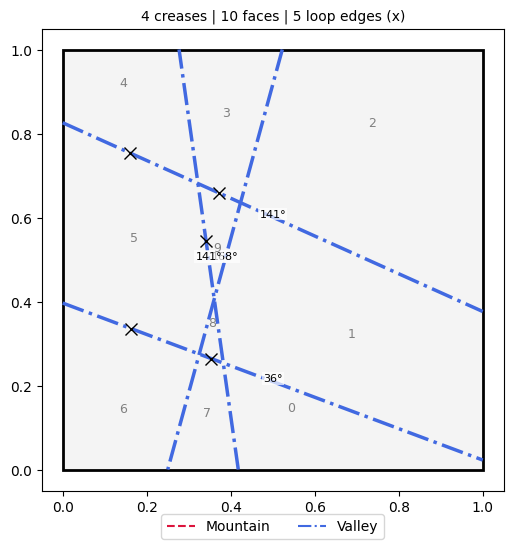

Faces : 10
Hinges: 9 | loop edges: 5
Target angles (deg): [-141.2  -36.   140.8 -168.3  140.8 -168.3  168.3  168.3  140.8]


In [ ]:
# ============================================================
# CELL 6 — Generate a random pattern, plot it, build XML
# ============================================================

rng = np.random.default_rng(2)
genome = rng.uniform(GENE_LOW, GENE_HIGH)

creases = decode_genome(genome)
pat     = build_pattern(creases)

print("Valid :", pat.valid, pat.reason)
plot_pattern(creases, pat)

if pat.valid:
    xml_fold, info = generate_xml(pat, creases)
    target_angles = info["targets"]
    print("Faces :", info["n_faces"])
    print("Hinges:", info["n_hinges"], "| loop edges:", info["n_loops"])
    print("Target angles (deg):", np.round(np.rad2deg(target_angles), 1))

In [ ]:
genome

array([ 0.26161213,  0.29849114,  0.81422574,  0.09191594,  0.62895015,
        0.72856053,  0.18790107,  0.05514663,  0.27496937,  0.65743301,
        0.3912267 ,  0.15006226,  0.43263079,  0.6692973 ,  0.42278467,
        0.6331844 ,  2.93698671,  0.68306482,  0.39162483,  0.18725257,
        0.34596067,  0.51106597,  2.45804121,  0.77556394,  0.3181466 ,
        0.9242169 ,  0.47090989,  0.69375884, -2.46798927,  0.10454356,
        0.20190745,  0.88444967,  0.67981146,  0.84923632,  0.90751984,
        0.4065424 ,  0.51657819,  0.59344352,  0.86211798,  0.43818617,
        2.4645173 ,  0.61371694,  0.82935613,  0.49805605,  0.69251813,
        0.33902537,  0.14343572,  0.21622339])

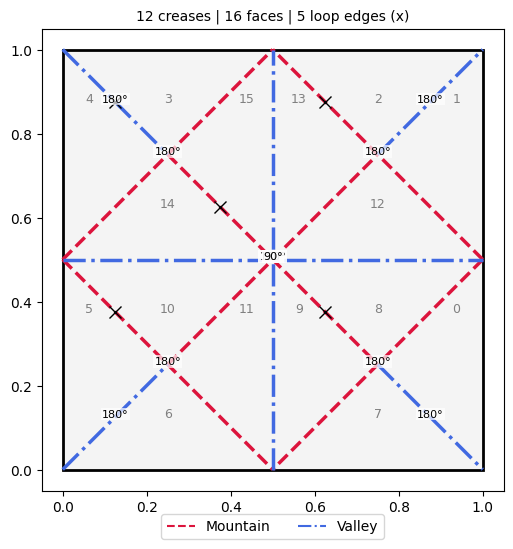

In [ ]:
# ============================================================
# CELL 6c — Manual crease pattern (direct Crease objects)
# ============================================================

creases = [
    Crease(p1=(1.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180), gene=1),# vertical valley, x = 0.5
    Crease(p1=(0.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180), gene=2),
    Crease(p1=(1.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180), gene=3),
    Crease(p1=(0.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180), gene=4),
    Crease(p1=(0.25, 0.25), p2=(0.75, 0.75), angle=np.deg2rad(-180), gene=5),
    Crease(p1=(0.25, 0.75), p2=(0.75, 0.25), angle=np.deg2rad(-180), gene=6),
    Crease(p1=(0, 0), p2=(0.25, 0.25), angle=np.deg2rad(180), gene=5),
    Crease(p1=(0.75, 0.75), p2=(1,1), angle=np.deg2rad(180), gene=6),
    Crease(p1=(0,1), p2=(0.25, 0.75), angle=np.deg2rad(180), gene=5),
    Crease(p1=(0.75, 0.25), p2=(1,0), angle=np.deg2rad(180), gene=6),
    Crease(p1=(0.5, 0.0), p2=(0.5, 1.0), angle=np.deg2rad(90), gene=7),   # vertical valley, x = 0.5
    Crease(p1=(0.0, 0.5), p2=(1.0, 0.5), angle=np.deg2rad(90), gene=8),

]

pat = build_pattern(creases)
plot_pattern(creases, pat)

xml_fold, info = generate_xml(pat, creases)
target_angles = info["targets"]

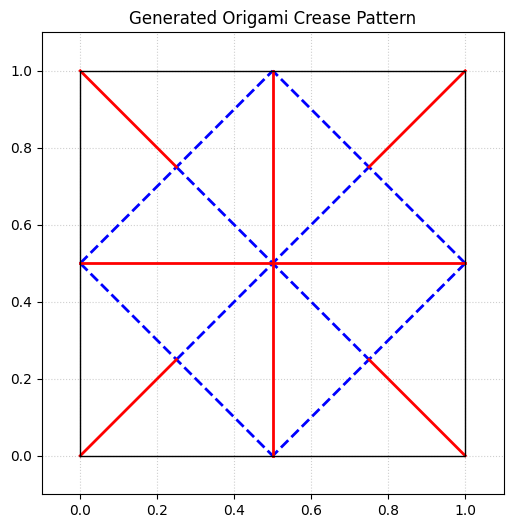

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define a simple container class mirroring your structure
class Crease:
    def __init__(self, p1, p2, angle, gene):
        self.p1 = np.array(p1)
        self.p2 = np.array(p2)
        self.angle = angle
        self.gene = gene

# Your exact crease data
creases = [
    Crease(p1=(1.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180), gene=1),
    Crease(p1=(0.0, 0.5), p2=(0.5, 0.0), angle=np.deg2rad(-180), gene=2),
    Crease(p1=(1.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180), gene=3),
    Crease(p1=(0.0, 0.5), p2=(0.5, 1.0), angle=np.deg2rad(-180), gene=4),
    Crease(p1=(0.25, 0.25), p2=(0.75, 0.75), angle=np.deg2rad(-180), gene=5),
    Crease(p1=(0.25, 0.75), p2=(0.75, 0.25), angle=np.deg2rad(-180), gene=6),
    Crease(p1=(0, 0), p2=(0.25, 0.25), angle=np.deg2rad(180), gene=5),
    Crease(p1=(0.75, 0.75), p2=(1,1), angle=np.deg2rad(180), gene=6),
    Crease(p1=(0,1), p2=(0.25, 0.75), angle=np.deg2rad(180), gene=5),
    Crease(p1=(0.75, 0.25), p2=(1,0), angle=np.deg2rad(180), gene=6),
    Crease(p1=(0.5, 0.0), p2=(0.5, 1.0), angle=np.deg2rad(90), gene=7),
    Crease(p1=(0.0, 0.5), p2=(1.0, 0.5), angle=np.deg2rad(90), gene=8),
]

# Set up the plot
plt.figure(figsize=(6, 6))
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.gca().set_aspect('equal', adjustable='box')
plt.title("Generated Origami Crease Pattern")

# Standard origami convention: Red = Mountain, Blue = Valley
for c in creases:
    # Check if the angle represents a Mountain vs. Valley fold orientation
    color = 'red' if c.angle > 0 else 'blue'
    linestyle = '-' if c.angle > 0 else '--'

    # Plot the line segment
    plt.plot([c.p1[0], c.p2[0]], [c.p1[1], c.p2[1]], color=color, linestyle=linestyle, linewidth=2)

# Draw paper boundary (0 to 1 square)
plt.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color='black', linewidth=1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()



In [ ]:
# ============================================================
# CELL 7 — Build MuJoCo model from generated XML
# ============================================================

import mujoco
import mediapy as media

model_fold = mujoco.MjModel.from_xml_string(xml_fold)
data_fold  = mujoco.MjData(model_fold)

hinge_adr = np.array([model_fold.joint(h["name"]).qposadr[0] for h in info["hinges"]], dtype=int)
root_adr  = model_fold.joint("root").qposadr[0]
tx_qpos   = model_fold.joint("table_x").qposadr[0]
tz_qpos   = model_fold.joint("table_z").qposadr[0]

print("Bodies   :", model_fold.nbody)
print("Joints   :", model_fold.njnt)
print("Actuators:", model_fold.nu)
print("Equality constraints:", model_fold.neq)

Bodies   : 18
Joints   : 18
Actuators: 15
Equality constraints: 10


In [ ]:
# ============================================================
# CELL 8 — Fold on a vibrating table (replaces old drive_table)
# ============================================================

def drive_table(m, d, t):
    w  = 2 * np.pi * VIB_FREQ
    jx, jz = m.joint("table_x"), m.joint("table_z")
    d.qpos[jx.qposadr[0]] = VIB_AMP_X * np.sin(w * t)
    d.qvel[jx.dofadr[0]]  = VIB_AMP_X * w * np.cos(w * t)
    d.qpos[jz.qposadr[0]] = VIB_AMP_Z * np.sin(w * t)
    d.qvel[jz.dofadr[0]]  = VIB_AMP_Z * w * np.cos(w * t)


mujoco.mj_resetData(model_fold, data_fold)

renderer = mujoco.Renderer(model_fold, 720, 1280)
cam = mujoco.MjvCamera()
cam.lookat[:] = [0, 0, 0.1]
cam.distance, cam.azimuth, cam.elevation = 2.5, 90, -30

FPS, T_FOLD, T_TOTAL = 30, 3.0, 8.0
frames = []

while data_fold.time < T_TOTAL:

    t = min(data_fold.time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)                     # smoothstep
    data_fold.ctrl[:] = s * target_angles

    drive_table(model_fold, data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)

    if len(frames) < data_fold.time * FPS:
        renderer.update_scene(data_fold, camera=cam)
        frames.append(renderer.render())

media.show_video(frames, fps=FPS)

print("Hinge angles (deg):", np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2))
print("Target angles (deg):", np.round(np.rad2deg(target_angles), 2))

This browser does not support the video tag.


Hinge angles (deg): [-112.91 -179.94  109.95  179.58 -166.99  166.93  106.73  179.9  -179.94
  109.91  179.58  167.07 -167.01  106.69  179.91]
Target angles (deg): [ 176.4 -176.4   90.   176.4 -176.4  176.4   90.   176.4 -176.4   90.
  176.4  176.4 -176.4   90.   176.4]


In [ ]:
# ============================================================
# CELL 8c — Proyeksi sudut ke lintasan lipat yang loop-nya tertutup
# ============================================================

from scipy.optimize import least_squares

mujoco.mj_resetData(model_fold, data_fold)
_d = mujoco.MjData(model_fold)          # data khusus untuk kinematika

def closure_residual(q_h):
    mujoco.mj_resetData(model_fold, _d)
    _d.qpos[hinge_adr] = q_h
    mujoco.mj_kinematics(model_fold, _d)
    res = []
    for k in range(model_fold.neq):
        b1, b2 = model_fold.eq_obj1id[k], model_fold.eq_obj2id[k]
        a1 = model_fold.eq_data[k, 0:3]
        a2 = model_fold.eq_data[k, 3:6]
        p1 = _d.xpos[b1] + _d.xmat[b1].reshape(3, 3) @ a1
        p2 = _d.xpos[b2] + _d.xmat[b2].reshape(3, 3) @ a2
        res.extend(p1 - p2)
    return np.array(res)

N_STAGE  = 60
W_CLOSE  = 1e3                           # makin besar = penutupan loop makin diutamakan
s_grid   = np.linspace(0, 1, N_STAGE + 1)
path     = np.zeros((N_STAGE + 1, len(hinge_adr)))
close_err = np.zeros(N_STAGE + 1)

q_prev = np.zeros(len(hinge_adr))
for n, s in enumerate(s_grid):
    desired = s * target_angles
    f = lambda q: np.concatenate([W_CLOSE * closure_residual(q), q - desired])
    sol = least_squares(f, q_prev)       # mulai dari solusi sebelumnya -> tetap di cabang yang sama
    path[n]      = sol.x
    close_err[n] = np.abs(closure_residual(sol.x)).max() if model_fold.neq else 0.0
    q_prev       = sol.x

print("Sudut target (deg)   :", np.round(np.rad2deg(target_angles), 1))
print("Sudut yang tercapai  :", np.round(np.rad2deg(path[-1]), 1))
print("Sisa loop terburuk (m):", float(close_err.max()))
print("Selisih rata-rata dari target (deg):",
      round(float(np.rad2deg(np.mean(np.abs(path[-1] - target_angles)))), 2))

Sudut target (deg)   : [ 176.4 -176.4   90.   176.4 -176.4  176.4   90.   176.4 -176.4   90.
  176.4  176.4 -176.4   90.   176.4]
Sudut yang tercapai  : [ 176.4 -180.   180.2  180.  -176.4  176.4  179.8  180.  -180.   180.2
  180.   176.4 -176.4  179.8  180. ]
Sisa loop terburuk (m): 6.496489425134033e-05
Selisih rata-rata dari target (deg): 25.44


In [ ]:
# ============================================================
# CELL 8d — Simulasi memakai lintasan yang konsisten
# ============================================================

T_FOLD, T_TOTAL, FPS = 4.0, 8.0, 30

def ctrl_at(time):
    t = min(time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)
    return np.array([np.interp(s, s_grid, path[:, h]) for h in range(path.shape[1])])

mujoco.mj_resetData(model_fold, data_fold)
frames, worst = [], 0.0

while data_fold.time < T_TOTAL:
    data_fold.ctrl[:] = ctrl_at(data_fold.time)
    drive_table(model_fold, data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)

    eq = data_fold.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    if eq.any():
        worst = max(worst, float(np.abs(data_fold.efc_pos[eq]).max()))

    if len(frames) < data_fold.time * FPS:
        renderer.update_scene(data_fold, camera=cam)
        frames.append(renderer.render())

media.show_video(frames, fps=FPS)
print("Violation terburuk (m):", round(worst, 5))
print("Sudut aktual (deg):", np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2))

This browser does not support the video tag.


Violation terburuk (m): 0.00509
Sudut aktual (deg): [ 176.71 -180.    180.    180.   -176.47  176.47  180.    180.   -180.
  180.02  180.    176.64 -176.64  179.98  180.  ]


In [ ]:
# ============================================================
# CELL D1 — Diagnose: why doesn't it reach the target?
# ============================================================

def test_fold(contacts=True, gravity=True, steps=3000):
    mujoco.mj_resetData(model_fold, data_fold)
    if contacts:
        model_fold.opt.disableflags &= ~int(mujoco.mjtDisableBit.mjDSBL_CONTACT.value)
    else:
        model_fold.opt.disableflags |= int(mujoco.mjtDisableBit.mjDSBL_CONTACT.value)
    model_fold.opt.gravity[:] = [0, 0, -9.81 if gravity else 0]

    data_fold.ctrl[:] = target_angles
    for _ in range(steps):
        mujoco.mj_step(model_fold, data_fold)

    eq = data_fold.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    print(f"contacts={contacts}, gravity={gravity}")
    for h, a, t in zip(info["hinges"], data_fold.qpos[hinge_adr], target_angles):
        print(f"  {h['name']}: target {np.rad2deg(t):7.1f}   actual {np.rad2deg(a):7.1f}")
    print("  loop edges:", info["n_loops"],
          "| max loop violation:",
          round(float(np.abs(data_fold.efc_pos[eq]).max()), 4) if eq.any() else 0.0)

test_fold(contacts=True,  gravity=True)    # your normal setup
test_fold(contacts=False, gravity=False)   # nothing in the way

contacts=True, gravity=True
  crease_0: target   176.4   actual  -112.3
  crease_1: target  -176.4   actual  -179.9
  crease_2: target    90.0   actual   110.1
  crease_3: target   176.4   actual   179.6
  crease_4: target  -176.4   actual  -166.8
  crease_5: target   176.4   actual   166.8
  crease_6: target    90.0   actual   106.8
  crease_7: target   176.4   actual   179.9
  crease_8: target  -176.4   actual  -179.9
  crease_9: target    90.0   actual   110.1
  crease_10: target   176.4   actual   179.6
  crease_11: target   176.4   actual   166.8
  crease_12: target  -176.4   actual  -166.8
  crease_13: target    90.0   actual   106.8
  crease_14: target   176.4   actual   179.9
  loop edges: 5 | max loop violation: 0.0006
contacts=False, gravity=False
  crease_0: target   176.4   actual  -112.2
  crease_1: target  -176.4   actual  -179.9
  crease_2: target    90.0   actual   110.2
  crease_3: target   176.4   actual   179.6
  crease_4: target  -176.4   actual  -166.9
  crease_5: 

In [ ]:
# ============================================================
# CELL D2 — Diagnose: what is holding the hinge back?
# ============================================================

# rebuild fresh from the current XML (rules out a stale model_fold / hinge_adr)
m = mujoco.MjModel.from_xml_string(xml_fold)
d = mujoco.MjData(m)
m.opt.disableflags |= mujoco.mjtDisableBit.mjDSBL_CONTACT
m.opt.gravity[:] = 0

j = m.joint("crease_0")
print("joint range (deg)  :", np.rad2deg(j.range))
print("joint limited      :", j.limited)
print("joint damping/arm. :", m.dof_damping[j.dofadr[0]], m.dof_armature[j.dofadr[0]])
print("actuator kp        :", m.actuator_gainprm[0, :3])
print("actuator forcerange:", m.actuator_forcerange[0], "limited:", m.actuator_forcelimited[0])
print("actuator ctrlrange :", m.actuator_ctrlrange[0], "limited:", m.actuator_ctrllimited[0])
print("body masses        :", np.round(m.body_mass[1:], 4))
print("dof inertia (diag) :", np.round(m.dof_M0[:], 5))

d.ctrl[:] = target_angles
qadr = j.qposadr[0]
print("\n time   ctrl    angle   act.force")
for step in range(3000):
    mujoco.mj_step(m, d)
    if step % 250 == 0:
        print(f"{d.time:5.2f}  {np.rad2deg(d.ctrl[0]):6.1f}  "
              f"{np.rad2deg(d.qpos[qadr]):6.2f}  {d.actuator_force[0]:8.3f}")

joint range (deg)  : [-180.00042092  180.00042092]
joint limited      : [1]
joint damping/arm. : 0.05 0.001
actuator kp        : [20.  0.  0.]
actuator forcerange: [-10.  10.] limited: True
actuator ctrlrange : [-3.1416  3.1416] limited: True
body masses        : [1.00e+03 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02
 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02 1.25e-02
 1.25e-02]
dof inertia (diag) : [1.000e+03 1.000e+03 2.000e-01 2.000e-01 2.000e-01 2.917e-02 5.139e-02
 8.056e-02 9.330e-03 2.157e-02 8.290e-03 1.520e-03 1.260e-03 4.910e-03
 2.040e-03 1.260e-03 2.157e-02 8.290e-03 1.520e-03 1.260e-03 4.910e-03
 2.040e-03 1.260e-03]

 time   ctrl    angle   act.force
 0.00   176.4    0.27    10.000
 0.25   176.4  -63.58    10.000
 0.50   176.4  -111.61    10.000
 0.75   176.4  -112.17    10.000
 1.00   176.4  -112.18    10.000
 1.25   176.4  -112.18    10.000
 1.50   176.4  -112.18    10.000
 1.75   176.4  -112.18    10.000
 2.00   176.4  -112.18    

In [ ]:
# ============================================================
# CELL D3 — Ukur "sobek" per loop edge dan jarak engsel
# ============================================================

mujoco.mj_resetData(model_fold, data_fold)
model_fold.opt.disableflags &= ~int(mujoco.mjtDisableBit.mjDSBL_CONTACT.value)
model_fold.opt.gravity[:] = [0, 0, -9.81]

worst = 0.0
for step in range(4000):
    t = min(data_fold.time / 2.0, 1.0)
    s = t * t * (3 - 2 * t)
    data_fold.ctrl[:] = s * target_angles
    drive_table(model_fold, data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)

    eq = data_fold.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    v = float(np.abs(data_fold.efc_pos[eq]).max()) if eq.any() else 0.0
    worst = max(worst, v)
    if step % 500 == 0:
        print(f"t={data_fold.time:4.2f}  loop violation={v:.5f} m  "
              f"act.force max={np.abs(data_fold.actuator_force).max():.1f}")

print("Violation terburuk (m):", round(worst, 5))

t=0.00  loop violation=0.00000 m  act.force max=0.0
t=0.50  loop violation=0.00190 m  act.force max=9.7
t=1.00  loop violation=0.00467 m  act.force max=10.0
t=1.50  loop violation=0.00309 m  act.force max=10.0
t=2.00  loop violation=0.00108 m  act.force max=10.0
t=2.50  loop violation=0.00070 m  act.force max=10.0
t=3.00  loop violation=0.00069 m  act.force max=10.0
t=3.50  loop violation=0.00069 m  act.force max=10.0
Violation terburuk (m): 0.0077


In [ ]:
# ============================================================
# CELL 9 — Fitness function for the genetic algorithm
# ============================================================

from shapely.geometry import MultiPoint

def evaluate(genome, T_FOLD=2.0, T_TOTAL=4.0, vibrate=True):
    """genome -> dict with 'fitness' (higher is better). Edit the score at the bottom."""
    try:
        creases = decode_genome(genome)
        pat = build_pattern(creases)
        if not pat.valid:
            return dict(fitness=-1e3, reason=pat.reason)
        xml, inf = generate_xml(pat, creases)
        m = mujoco.MjModel.from_xml_string(xml)
    except Exception as ex:
        return dict(fitness=-1e3, reason=f"build error: {str(ex)[:80]}")

    d = mujoco.MjData(m)
    h_adr = np.array([m.joint(h["name"]).qposadr[0] for h in inf["hinges"]], dtype=int)

    while d.time < T_TOTAL:
        t = min(d.time / T_FOLD, 1.0)
        s = t * t * (3 - 2 * t)
        d.ctrl[:] = s * inf["targets"]
        if vibrate:
            drive_table(m, d, d.time)
        mujoco.mj_step(m, d)

    if not np.isfinite(d.qpos).all():
        return dict(fitness=-1e3, reason="unstable simulation")

    # how badly the closed-loop constraints are violated (0 = rigidly foldable)
    eq = d.efc_type == mujoco.mjtConstraint.mjCNSTR_EQUALITY
    violation = float(np.abs(d.efc_pos[eq]).max()) if eq.any() else 0.0

    # how far the actuated hinges are from their targets
    reach_err = float(np.mean(np.abs(d.qpos[h_adr] - inf["targets"]))) if len(h_adr) else 0.0

    # footprint of the folded paper (convex hull of all face-triangle centres, xy)
    table_id = m.body("table").id
    ids = [g for g in range(m.ngeom) if m.geom_bodyid[g] != table_id]
    footprint = MultiPoint(d.geom_xpos[ids, :2]).convex_hull.area

    # ---- placeholder score: fold small, keep constraints satisfied ----
    fitness = -footprint - 5.0 * violation - 1.0 * reach_err

    return dict(fitness=fitness, footprint=footprint, violation=violation,
                reach_err=reach_err, n_faces=inf["n_faces"], n_loops=inf["n_loops"],
                n_creases=len(creases))


print(evaluate(genome))

{'fitness': -1.3447184410690605, 'footprint': 0.2523311429225802, 'violation': 0.006356537890740033, 'reach_err': 1.06060460869278, 'n_faces': 10, 'n_loops': 5, 'n_creases': 4}
